<font size = 1 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font>  


## Grokking

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
print(torch.cuda.is_available())

print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Sin GPU")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


True
NVIDIA GeForce MX450


In [14]:


# 1. Configuración de datos: Aritmética modular (a + b) % P
P = 83  # Número primo
X_data = []
y_data = []

for a in range(P):
    for b in range(P):
        X_data.append([a, b])
        y_data.append((a + b) % P)

X = torch.tensor(X_data, dtype=torch.float32)
y = torch.tensor(y_data, dtype=torch.long)


# División en Entrenamiento (50%) y validation (50%)
torch.manual_seed(2026)
perm = torch.randperm(len(X))
split = len(X) // 2

validation_idx, train_idx = perm[:split], perm[split:]
X_train, y_train = X[train_idx], y[train_idx]
X_validation, y_validation = X[validation_idx], y[validation_idx]

X_train = X_train.to(device)
y_train = y_train.to(device)
X_validation = X_validation.to(device)
y_validation = y_validation.to(device)

# 2. Definición del modelo (Red neuronal simple de 2 capas ocultas)
class SmallMLP(nn.Module):
    def __init__(self, p):
        super().__init__()
        self.embed = nn.Embedding(p, 32)
        self.fc1 = nn.Linear(64, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, p)

    def forward(self, x):
        # x shape: [batch, 2] -> obtenemos embeddings de a y b y los concatenamos
        a_emb = self.embed(x[:, 0].long())
        b_emb = self.embed(x[:, 1].long())
        out = torch.cat([a_emb, b_emb], dim=1)
        out = self.relu(self.fc1(out))
        return self.fc2(out)


model = SmallMLP(P).to(device)
criterion = nn.CrossEntropyLoss()

# El Weight Decay (regularización L2) es clave para estimular el fenómeno de grokking
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=2)

# 3. Bucle de entrenamiento largo
epochs = 5000
train_accs, validation_accs = [], []

print("Entrenando el modelo...")
for epoch in range(1, epochs + 1):
    model.train()
    optimizer.zero_grad()
    out = model(X_train)
    loss = criterion(out, y_train)
    loss.backward()
    optimizer.step()

    # Evaluación periódica
    if epoch % 100 == 0 or epoch == 1:
        model.eval()
        with torch.no_grad():
            train_preds = model(X_train).argmax(dim=1)
            validation_preds = model(X_validation).argmax(dim=1)
            
            tr_acc = (train_preds == y_train).float().mean().item()
            te_acc = (validation_preds == y_validation).float().mean().item()
            
            train_accs.append(tr_acc)
            validation_accs.append(te_acc)

        if epoch % 100 == 0:
            print(f"Época {epoch:5d} | Train Acc: {tr_acc * 100:.1f}% | validation Acc: {te_acc * 100:.1f}%")


Entrenando el modelo...
Época   100 | Train Acc: 12.2% | validation Acc: 0.0%
Época   200 | Train Acc: 29.7% | validation Acc: 0.0%
Época   300 | Train Acc: 49.4% | validation Acc: 0.1%
Época   400 | Train Acc: 64.8% | validation Acc: 0.1%
Época   500 | Train Acc: 77.0% | validation Acc: 0.1%
Época   600 | Train Acc: 86.0% | validation Acc: 0.1%
Época   700 | Train Acc: 92.2% | validation Acc: 0.1%
Época   800 | Train Acc: 96.2% | validation Acc: 0.4%
Época   900 | Train Acc: 98.3% | validation Acc: 0.9%
Época  1000 | Train Acc: 99.5% | validation Acc: 1.9%
Época  1100 | Train Acc: 99.8% | validation Acc: 3.9%
Época  1200 | Train Acc: 100.0% | validation Acc: 7.9%
Época  1300 | Train Acc: 100.0% | validation Acc: 14.2%
Época  1400 | Train Acc: 100.0% | validation Acc: 23.3%
Época  1500 | Train Acc: 100.0% | validation Acc: 36.2%
Época  1600 | Train Acc: 100.0% | validation Acc: 49.2%
Época  1700 | Train Acc: 100.0% | validation Acc: 60.4%
Época  1800 | Train Acc: 100.0% | validation Ac

In [15]:
# 4. Visualización del Grokking

x_axis = list(range(0, epochs+2, 100))[1:]

print(len(x_axis))
print(len(train_accs[:-1]))
print(x_axis)
print(train_accs[:-1])


50
50
[100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100, 2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900, 3000, 3100, 3200, 3300, 3400, 3500, 3600, 3700, 3800, 3900, 4000, 4100, 4200, 4300, 4400, 4500, 4600, 4700, 4800, 4900, 5000]
[0.010740202851593494, 0.12191581726074219, 0.2966618239879608, 0.49433961510658264, 0.6481857895851135, 0.7703918814659119, 0.8597967624664307, 0.9224963784217834, 0.9622641205787659, 0.9834542870521545, 0.9953555464744568, 0.9982582926750183, 0.9997097253799438, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


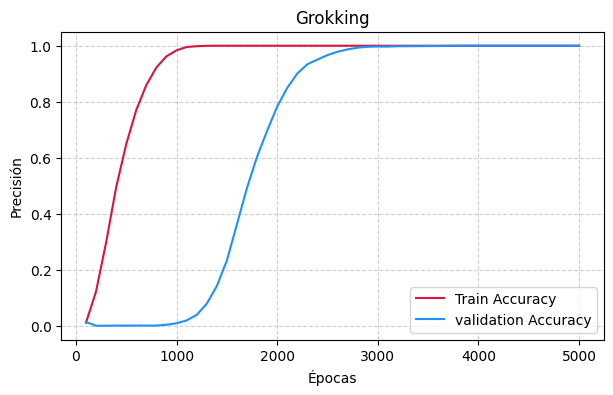

In [16]:
# 4. Visualización del Grokking
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
x_axis = np.array(range(0, epochs+2, 100))[1:]
plt.plot(x_axis, np.array(train_accs[:-1]), label="Train Accuracy", color="crimson")
plt.plot(x_axis, np.array(validation_accs[:-1]), label="validation Accuracy", color="dodgerblue")
plt.title("Grokking")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()